## Ad Targeting Optimization Using User Segmentation

### Business Problem

A digital advertising company currently displays advertisements to all users without differentiation, leading to inefficient ad spending and suboptimal Click-Through Rates (CTR).

The objective of this project is to identify meaningful user segments using Unsupervised Learning techniques and leverage these segments to improve ad targeting efficiency.

Two approaches are evaluated:

1. Traditional Machine Learning (K-Means Clustering)
2. Deep Learning (Autoencoder + K-Means Clustering)

The resulting segments are analyzed based on CTR to identify high-value and low-value audiences and provide actionable business recommendations.

In [3]:
import numpy as np
import pandas as pd

In [4]:
import pandas as pd

url = "https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/169/383/original/ad_click_dataset.csv?1764943571"


df = pd.read_csv(url)
df.to_csv("ad_click_dataset.csv", index=False)


In [5]:
df.head(5)

,id,full_name,age,gender,device_type,ad_position,browsing_history,time_of_day,click
0,670,User670,22.0,NaN,Desktop,Top,Shopping,Afternoon,1
1,3044,User3044,NaN,Male,Desktop,Top,NaN,NaN,1
2,5912,User5912,41.0,Non-Binary,NaN,Side,Education,Night,1
3,5418,User5418,34.0,Male,NaN,NaN,Entertainment,Evening,1
4,9452,User9452,39.0,Non-Binary,NaN,NaN,Social Media,Morning,0


### Dataset Overview

The dataset contains demographic and behavioral information about users who were shown advertisements.

### Features

- Age
- Gender
- Device Type
- Ad Position
- Browsing History
- Time of Day
- Click (Target Variable)

### Objective

Although the dataset contains a click indicator, clustering will be performed without using the click variable. Click behavior will be analyzed after segmentation to evaluate the business value of each cluster.

In [6]:
df.shape

(10000, 9)

### Data Quality Assessment

Before performing clustering, it is important to evaluate the completeness and quality of the data.

The following analysis identifies missing values across all features to determine the required preprocessing strategy.

In [7]:
df.isnull().sum()

id                     0
full_name              0
age                 4766
gender              4693
device_type         2000
ad_position         2000
browsing_history    4782
time_of_day         2000
click                  0
dtype: int64

### Missing Value Treatment Strategy

The dataset contains substantial missing values in age, gender, and browsing history.

#### Numerical Features

- Age is imputed using the median value.
- Median is preferred because it is less sensitive to outliers.

#### Categorical Features

Missing categorical values are replaced with "Unknown".

This approach preserves potentially useful information because missingness itself may represent a meaningful user behavior pattern.

In [8]:
print(df.shape)

print(df.info())

print(df.describe())

for col in df.select_dtypes(include="object"):
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))

(10000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                10000 non-null  int64  
 1   full_name         10000 non-null  object 
 2   age               5234 non-null   float64
 3   gender            5307 non-null   object 
 4   device_type       8000 non-null   object 
 5   ad_position       8000 non-null   object 
 6   browsing_history  5218 non-null   object 
 7   time_of_day       8000 non-null   object 
 8   click             10000 non-null  int64  
dtypes: float64(1), int64(2), object(6)
memory usage: 703.2+ KB
None
                 id          age         click
count  10000.000000  5234.000000  10000.000000
mean    5060.211400    40.197363      0.650000
std     2861.758265    13.126420      0.476993
min        5.000000    18.000000      0.000000
25%     2529.000000    29.000000      0.000000
50%     5218.0

In [9]:
df = df.drop(columns=["id", "full_name"])

In [10]:
df["age"] = df["age"].fillna(df["age"].median())

In [11]:
cat_cols = [
    "gender",
    "device_type",
    "ad_position",
    "browsing_history",
    "time_of_day"
]

for col in cat_cols:
    df[col] = df[col].fillna("Unknown")

In [12]:
y_click = df["click"]

X = df.drop(columns=["click"])

### Feature Engineering

Clustering algorithms require numerical inputs.

Categorical variables are converted into numerical representations using One-Hot Encoding.

This allows the clustering algorithm to measure similarities across all demographic and behavioral attributes.

In [13]:
X_encoded = pd.get_dummies(
    X,
    drop_first=False
)

print(X_encoded.shape)

(10000, 24)


### Feature Scaling

K-Means is a distance-based algorithm.

Standardization is applied to ensure all features contribute equally to distance calculations and prevent features with larger scales from dominating the clustering process.

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_encoded)

### K-Means Clustering (Machine Learning Approach)

K-Means clustering is used as the baseline segmentation model.

The optimal number of clusters is evaluated using:

- Silhouette Score (Higher is Better)
- Davies-Bouldin Index (Lower is Better)

The goal is to identify the number of segments that provides strong separation while remaining practical for business implementation.

In [15]:
K = range(2,11)

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

results = []

for k in range(2,11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_scaled)

    sil = silhouette_score(
        X_scaled,
        labels
    )

    db = davies_bouldin_score(
        X_scaled,
        labels
    )

    results.append(
        [k, sil, db]
    )

results_df = pd.DataFrame(
    results,
    columns=[
        "K",
        "Silhouette",
        "DB_Index"
    ]
)

print(results_df)

    K  Silhouette  DB_Index
0   2    0.067298  3.722797
1   3    0.092540  3.212996
2   4    0.117974  2.687395
3   5    0.136290  2.523021
4   6    0.124590  2.449360
5   7    0.123363  2.341552
6   8    0.121682  2.222371
7   9    0.102741  2.296461
8  10    0.108853  2.195781


### K-Means Results

The evaluation indicates that K = 5 provides the most suitable balance between cluster quality and business usability.

While larger values of K may slightly improve certain metrics, maintaining a manageable number of segments is important for practical marketing deployment.

In [16]:
df["click"].value_counts(normalize=True)

click
1    0.65
0    0.35
Name: proportion, dtype: float64

In [17]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=20
)

clusters = kmeans.fit_predict(X_scaled)

df_analysis = df.copy()
df_analysis["cluster"] = clusters

### K-Means Cluster Profiling

After selecting the optimal number of clusters, the resulting segments are analyzed based on:

- Age
- Device Type
- Browsing Behavior
- Time of Day
- Click-Through Rate (CTR)

This helps translate mathematical clusters into actionable business personas.

In [18]:
df_analysis["cluster"].value_counts()

cluster
4    4782
1    2005
2    1175
3    1054
0     984
Name: count, dtype: int64

In [19]:
df_analysis.groupby("cluster")["click"].mean()

cluster
0    0.645325
1    0.609975
2    0.687660
3    0.635674
4    0.661648
Name: click, dtype: float64

In [20]:
df_analysis.groupby("cluster")["age"].mean()

cluster
0    39.763720
1    40.269327
2    38.309362
3    41.255218
4    39.792137
Name: age, dtype: float64

In [21]:
pd.crosstab(
    df_analysis["cluster"],
    df_analysis["device_type"],
    normalize="index"
)

device_type,Desktop,Mobile,Tablet,Unknown
cluster,,,,
0,0.339431,0.212398,0.241870,0.206301
1,0.240399,0.282294,0.282793,0.194514
2,0.284255,0.264681,0.242553,0.208511
3,0.237192,0.355787,0.209677,0.197343
4,0.283145,0.248432,0.268925,0.199498


In [22]:
pd.crosstab(
    df_analysis["cluster"],
    df_analysis["browsing_history"],
    normalize="index"
)

browsing_history,Education,Entertainment,News,Shopping,Social Media,Unknown
cluster,,,,,,
0,0.000000,0.0,0.000000,1.0,0.0,0.0
1,0.513217,0.0,0.486783,0.0,0.0,0.0
2,0.000000,1.0,0.000000,0.0,0.0,0.0
3,0.000000,0.0,0.000000,0.0,1.0,0.0
4,0.000000,0.0,0.000000,0.0,0.0,1.0


In [23]:
pd.crosstab(
    df_analysis["cluster"],
    df_analysis["time_of_day"],
    normalize="index"
)

time_of_day,Afternoon,Evening,Morning,Night,Unknown
cluster,,,,,
0,0.239837,0.162602,0.217480,0.168699,0.211382
1,0.190025,0.201995,0.230424,0.187032,0.190524
2,0.217872,0.192340,0.192340,0.200000,0.197447
3,0.168880,0.202087,0.223909,0.200190,0.204934
4,0.201798,0.199498,0.206608,0.190924,0.201171


### Autoencoder + K-Means (Deep Learning Approach)

Traditional K-Means operates directly on engineered features.

An Autoencoder is introduced to learn compressed latent representations of user behavior.

The latent features capture hidden relationships between demographic and behavioral variables and may produce more meaningful user segments.

In [24]:
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

input_dim = X_scaled.shape[1]

input_layer = Input(shape=(input_dim,))

encoder = Dense(64, activation='relu')(input_layer)
encoder = Dense(32, activation='relu')(encoder)

latent = Dense(
    8,
    activation='relu',
    name='latent_layer'
)(encoder)

decoder = Dense(32, activation='relu')(latent)
decoder = Dense(64, activation='relu')(decoder)

output_layer = Dense(
    input_dim,
    activation='linear'
)(decoder)

autoencoder = Model(
    inputs=input_layer,
    outputs=output_layer
)

autoencoder.compile(
    optimizer='adam',
    loss='mse'
)

autoencoder.summary()



Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 24)]              0         
                                                                 
 dense (Dense)               (None, 64)                1600      
                                                                 
 dense_1 (Dense)             (None, 32)                2080      
                                                                 
 latent_layer (Dense)        (None, 8)                 264       
                                                                 
 dense_2 (Dense)             (None, 32)                288       
                                                                 
 dense_3 (Dense)             (None, 64)                2112      
                                                                 
 dense_4 (Dense)             (None, 24)                1560

In [25]:
history = autoencoder.fit(
    X_scaled,
    X_scaled,
    epochs=50,
    batch_size=128,
    validation_split=0.2,
    shuffle=True,
    verbose=1
)

Epoch 1/50

63/63 [==============================] - 1s 4ms/step - loss: 0.9050 - val_loss: 0.7861
Epoch 2/50
63/63 [==============================] - 0s 2ms/step - loss: 0.7349 - val_loss: 0.6851
Epoch 3/50
63/63 [==============================] - 0s 2ms/step - loss: 0.6167 - val_loss: 0.5513
Epoch 4/50
63/63 [==============================] - 0s 2ms/step - loss: 0.4995 - val_loss: 0.4609
Epoch 5/50
63/63 [==============================] - 0s 2ms/step - loss: 0.4306 - val_loss: 0.4093
Epoch 6/50
63/63 [==============================] - 0s 2ms/step - loss: 0.3888 - val_loss: 0.3724
Epoch 7/50
63/63 [==============================] - 0s 2ms/step - loss: 0.3562 - val_loss: 0.3401
Epoch 8/50
63/63 [==============================] - 0s 2ms/step - loss: 0.3278 - val_loss: 0.3155
Epoch 9/50
63/63 [==============================] - 0s 2ms/step - loss: 0.3060 - val_loss: 0.2962
Epoch 10/50
63/63 [==============================] - 0s 2ms/step - loss: 0.2888 - val_loss: 0.2831
Epoch 11/50
63/63 

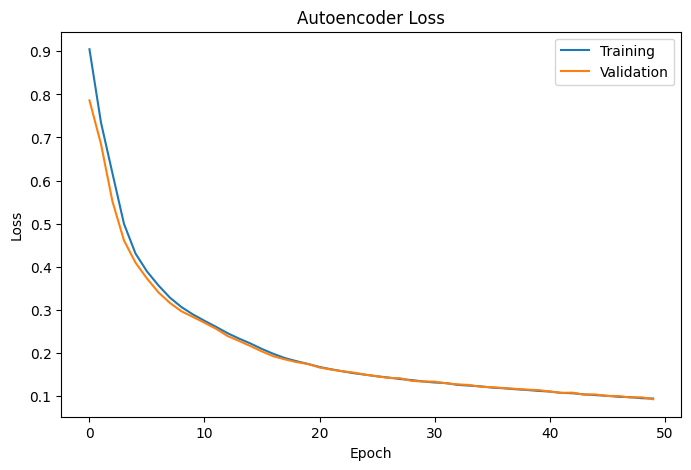

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title("Autoencoder Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend([
    "Training",
    "Validation"
])

plt.show()

## Autoencoder Training Performance

The reconstruction loss decreases consistently during training, indicating that the Autoencoder successfully learns a compressed representation of the original feature space.

The learned latent features are used as inputs for a second round of K-Means clustering.

In [27]:
encoder_model = Model(
    inputs=autoencoder.input,
    outputs=autoencoder.get_layer(
        'latent_layer'
    ).output
)

latent_features = encoder_model.predict(
    X_scaled
)

print(latent_features.shape)

313/313 [==============================] - 0s 773us/step
(10000, 8)


In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

ae_results = []

for k in range(2,11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(
        latent_features
    )

    sil = silhouette_score(
        latent_features,
        labels
    )

    db = davies_bouldin_score(
        latent_features,
        labels
    )

    ae_results.append(
        [k, sil, db]
    )

ae_results_df = pd.DataFrame(
    ae_results,
    columns=[
        "K",
        "Silhouette",
        "DB_Index"
    ]
)

ae_results_df

,K,Silhouette,DB_Index
0,2,0.399784,1.154487
1,3,0.411011,1.319604
2,4,0.396019,1.162070
3,5,0.427690,0.983905
4,6,0.345302,1.070046
5,7,0.334657,1.088919
6,8,0.323713,1.219350
7,9,0.303786,1.263420
8,10,0.282455,1.349772


## Autoencoder Clustering Results

The Autoencoder-based approach produces substantially higher Silhouette Scores and lower Davies-Bouldin Index values compared with traditional K-Means.

This indicates stronger cluster separation and improved internal cluster quality.

In [29]:
best_k = 5

ae_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

ae_clusters = ae_kmeans.fit_predict(
    latent_features
)

df_ae = df.copy()

df_ae["ae_cluster"] = ae_clusters

In [30]:
df_ae["ae_cluster"].value_counts()

ae_cluster
1    5304
0    1549
4    1143
2    1029
3     975
Name: count, dtype: int64

In [31]:
df_ae.groupby(
    "ae_cluster"
)["click"].mean()

ae_cluster
0    0.648160
1    0.657994
2    0.627794
3    0.591795
4    0.685039
Name: click, dtype: float64

In [32]:
df_ae.groupby(
    "ae_cluster"
)["age"].mean()

ae_cluster
0    40.469981
1    39.862274
2    40.590865
3    39.946667
4    38.334646
Name: age, dtype: float64

In [33]:
pd.crosstab(
    df_ae["ae_cluster"],
    df_ae["device_type"],
    normalize="index"
)

device_type,Desktop,Mobile,Tablet,Unknown
ae_cluster,,,,
0,0.349258,0.194319,0.236281,0.220142
1,0.263386,0.280354,0.260747,0.195513
2,0.235180,0.279883,0.279883,0.205053
3,0.246154,0.285128,0.286154,0.182564
4,0.292213,0.258093,0.245844,0.203850


In [34]:
pd.crosstab(
    df_ae["ae_cluster"],
    df_ae["browsing_history"],
    normalize="index"
)

browsing_history,Education,Entertainment,News,Shopping,Social Media,Unknown
ae_cluster,,,,,,
0,0.0,0.000000,0.000000,0.625565,0.320852,0.053583
1,0.0,0.006033,0.000189,0.002828,0.105015,0.885935
2,1.0,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.0,0.000000,1.000000,0.000000,0.000000,0.000000
4,0.0,1.000000,0.000000,0.000000,0.000000,0.000000


In [35]:
pd.crosstab(
    df_ae["ae_cluster"],
    df_ae["time_of_day"],
    normalize="index"
)

time_of_day,Afternoon,Evening,Morning,Night,Unknown
ae_cluster,,,,,
0,0.157521,0.176243,0.302776,0.141382,0.222079
1,0.220211,0.198718,0.182692,0.201923,0.196456
2,0.186589,0.226433,0.238095,0.152575,0.196307
3,0.192821,0.176410,0.222564,0.223590,0.184615
4,0.195976,0.197725,0.197725,0.205599,0.202975


### Model Comparison

Both approaches are compared using:

- Silhouette Score
- Davies-Bouldin Index
- CTR Separation

The objective is to identify the segmentation method that best distinguishes high-value users from low-value users.

## Business Recommendations

The discovered segments reveal substantial differences in user engagement behavior.

High-performing segments should receive increased advertising investment, while low-performing segments should receive reduced budget allocation.

This strategy improves overall campaign efficiency and maximizes return on advertising spend.

### Question 1

#### **K-Means**

- The optimal number of clusters is K=5, as it achieves the highest Silhouette Score (0.136) while remaining manageable from a marketing perspective.

#### **Autoencoder + KMeans**

- The optimal number of clusters is also K=5, producing the highest Silhouette Score (0.428) and lowest Davies-Bouldin Index (0.984). This indicates significantly better separation and compactness than the baseline K-Means model.

### Question 2
#### **Baseline Segment Characteristics**

#### The K-Means model identified five user segments primarily distinguished by browsing behavior:

- Cluster 0: Shopping users
- Cluster 1: Education and News users
- Cluster 2: Entertainment users
- Cluster 3: Social Media users
- Cluster 4: Users with unknown browsing history

- Device usage and age distributions were relatively similar across segments, indicating browsing context is the strongest differentiator of user behavior.

### Question 3

- The Autoencoder learned compressed latent representations of user behavior, combining information from age, device type, browsing history, and time of day into a lower-dimensional feature space. Although browsing behavior remained the dominant differentiator, the latent features significantly improved cluster compactness and separation.

- Compared with raw-feature K-Means:

    - Silhouette Score improved from 0.136 to 0.428
    - Davies-Bouldin Index improved from 2.523 to 0.984

- This indicates that users within each segment became more similar to one another while clusters became more distinct from each other. From a business perspective, this enables more precise audience targeting and reduces wasted advertising impressions.

### Question 4

#### **The Deep Learning approach outperformed the traditional K-Means approach.**

| Metric | KMeans | Autoencoder + KMeans |
|---------|--------:|--------------------:|
| *Silhouette* | 0.136 | 0.428 |
| *DB Index* | 2.523 | 0.984 |

- The Autoencoder learns compressed latent features that better capture hidden relationships between age, device type, browsing behavior, and time of day. Consequently, clusters become more compact and better separated, reducing overlap between user groups and enabling more precise targeting.


### Question 5

#### **The Autoencoder + KMeans model created the largest exploitable CTR difference**

| Model | Max CTR | Min CTR | Gap |
|---------|--------:|--------------------:|-------------:|
| *K-Means* | 68.77% | 60.99% | 7.78% |
| *Autoencoder + K-Means* | 68.50% | 59.18% | 9.32% |

- The larger CTR gap demonstrates a stronger ability to distinguish high-value users from low-value users.

### Question 6
#### **Highest Value Segment: Cluster 4**

**Characteristics:**

- Entertainment-focused users
    - Average age ≈ 38 years
    - Balanced device mix
    - CTR = 68.5%

- Recommendations:

    - Increase advertising spend
    - Prioritize premium ad inventory
    - Use visually engaging creatives
    - Promote entertainment, lifestyle, gaming and consumer products
    - Increase retargeting frequency

- Expected outcome:

    - Higher engagement
    - Higher CTR
    - Improved ROI

### Question 7
#### **Lowest Value Segment: Cluster 3**

- Characteristics:

    - News-focused users
    - Average age ≈ 40 years
    - CTR = 59.2%

- Recommendations:

    - Reduce display ad spending
    - Use contextual advertising only
    - Lower bidding strategy
    - Avoid expensive video placements

- Expected outcome:

    - Lower acquisition cost
    - Reduced wasted impressions
    - No major loss in revenue

### Question 8

We can justify

| Segment   | Action      |
|-----------|------------|
| Cluster 4 | +15% budget |
| Cluster 0 | +5% budget  |
| Cluster 1 | Maintain    |
| Cluster 2 | -5% budget  |
| Cluster 3 | -15% budget |

- This keeps total spend approximately constant while shifting investment toward higher CTR audiences.

### Question 9

#### **Deploy: Autoencoder + KMeans**

| Metric     | KMeans | Autoencoder |
|------------|--------|-------------|
| Silhouette | 0.136  | 0.428       |
| DB Index   | 2.523  | 0.984       |
| CTR Gap    | 7.78%  | 9.32%       |

- The Autoencoder produces mathematically superior clusters that translate directly into business value by more effectively separating high-engagement users from low-engagement users. This enables targeted budget allocation, improved CTR, and increased advertising ROI.

In [36]:
!pip install nbconvert
!jupyter nbconvert --to html Ad_Targeting_System.ipynb


[notice] A new release of pip is available: 23.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


[NbConvertApp] Converting notebook Ad_Targeting_System.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 410961 bytes to Ad_Targeting_System.html
